# Ejercicio 6 — Consumo energético

Análisis de los datos originales del centro. Se eliminan duplicados exactos; no se imputan valores ausentes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargamos los datos y eliminamos duplicados exactos.
df = pd.read_csv('centro_fp_monitorizacion.csv')
print('Dimensiones originales:', df.shape)
print('Duplicados:', df.duplicated().sum())
print('Ausentes por columna:', df.isna().sum())
df = df.drop_duplicates().copy()


Dimensiones originales: (363, 12)
Duplicados: 3
Ausentes por columna: fecha                0
dia                  0
hora                 0
aula                 0
alumnos              0
temperatura_c        0
humedad_pct          0
co2_ppm              6
consumo_kwh          0
dispositivos_wifi    0
desconexiones        0
latencia_ms          0
dtype: int64


In [2]:
df['ocupada'] = df['alumnos'] > 0
df['coste_eur'] = df['consumo_kwh'] * 0.20
df['revision'] = (~df['ocupada']) & (df['consumo_kwh'] > 1.8)
display(df.groupby('aula')[['consumo_kwh','coste_eur']].sum().round(2))
# Comparamos medias por hora, además de totales.
display(df.groupby(['aula','ocupada'])['consumo_kwh'].agg(['count','sum','mean']).round(2))
display(df.groupby('ocupada')['consumo_kwh'].agg(['count','sum','mean']).round(2))
revision = df[df['revision']]
display(revision)
display(revision.groupby(['aula','hora']).size())
revision.to_json('revision_energia.json', orient='records', indent=4, force_ascii=False)
print(df[['alumnos','temperatura_c','consumo_kwh']].corr())
print('Consumo en revisión:', revision['consumo_kwh'].sum())


,consumo_kwh,coste_eur
aula,,
A,374.10,74.82
B,324.94,64.99
C,325.83,65.17


count     sum  mean
aula ocupada                     
A    False       30   79.01  2.63
     True        90  295.09  3.28
B    False       30   17.73  0.59
     True        90  307.21  3.41
C    False       30   18.05  0.60
     True        90  307.78  3.42

,count,sum,mean
ocupada,,,
False,90,114.79,1.28
True,270,910.08,3.37


,fecha,dia,hora,aula,alumnos,temperatura_c,humedad_pct,co2_ppm,consumo_kwh,dispositivos_wifi,desconexiones,latencia_ms,ocupada,coste_eur,revision
9,2026-10-01,1,17,A,0,23.5,47.7,379.0,2.96,4,1,38.0,False,0.592,True
10,2026-10-01,1,18,A,0,23.3,55.9,414.0,2.91,4,1,41.6,False,0.582,True
11,2026-10-01,1,19,A,0,24.5,55.7,487.0,2.28,5,0,29.3,False,0.456,True
45,2026-10-02,2,17,A,0,23.6,41.4,502.0,2.71,2,0,30.2,False,0.542,True
46,2026-10-02,2,18,A,0,22.2,61.6,422.0,2.57,1,1,36.9,False,0.514,True
47,2026-10-02,2,19,A,0,24.5,48.3,386.0,2.14,1,1,36.0,False,0.428,True
81,2026-10-03,3,17,A,0,23.8,62.4,415.0,2.28,4,1,43.7,False,0.456,True
82,2026-10-03,3,18,A,0,21.9,41.7,486.0,2.34,4,0,35.4,False,0.468,True
83,2026-10-03,3,19,A,0,22.6,41.6,484.0,2.78,3,1,44.6,False,0.556,True
117,2026-10-04,4,17,A,0,24.3,44.7,365.0,3.18,1,0,26.6,False,0.636,True


aula  hora
A     17      10
      18      10
      19      10
dtype: int64

                alumnos  temperatura_c  consumo_kwh
alumnos        1.000000      -0.157263     0.886786
temperatura_c -0.157263       1.000000    -0.112413
consumo_kwh    0.886786      -0.112413     1.000000
Consumo en revisión: 79.01000000000002


<Figure size 800x400 with 0 Axes>

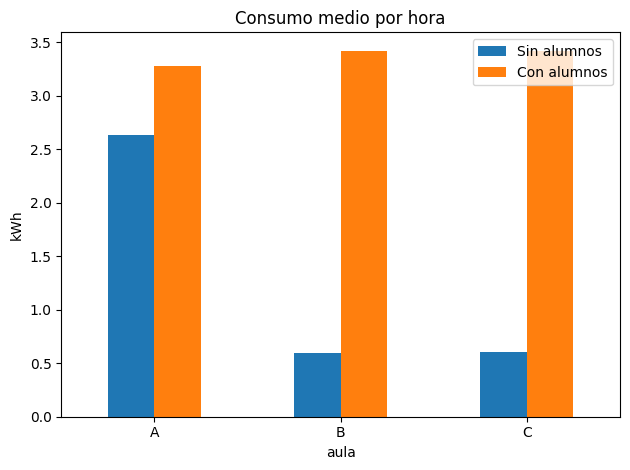

In [3]:
plt.figure(figsize=(8, 4))
df.groupby(['aula','ocupada'])['consumo_kwh'].mean().unstack().rename(columns={False:'Sin alumnos',True:'Con alumnos'}).plot.bar()
plt.title('Consumo medio por hora')
plt.ylabel('kWh')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.savefig('grafica_1.jpg', dpi=150)
plt.show()
plt.close()

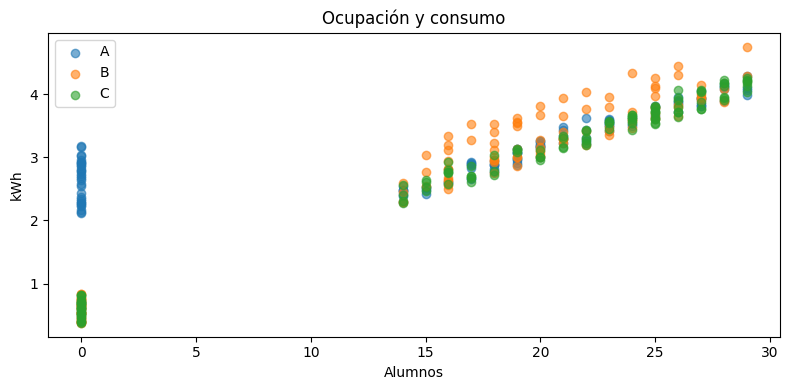

In [4]:
plt.figure(figsize=(8, 4))
for aula in df['aula'].unique():
    datos = df[df['aula']==aula]
    plt.scatter(datos['alumnos'],datos['consumo_kwh'],label=aula,alpha=0.6)
plt.xlabel('Alumnos')
plt.ylabel('kWh')
plt.title('Ocupación y consumo')
plt.legend()
plt.tight_layout()
plt.savefig('grafica_2.jpg', dpi=150)
plt.show()
plt.close()

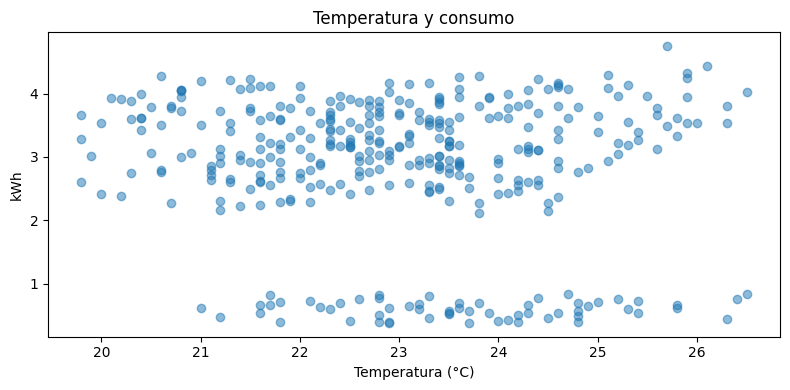

In [5]:
plt.figure(figsize=(8, 4))
plt.scatter(df['temperatura_c'],df['consumo_kwh'],alpha=0.5)
plt.xlabel('Temperatura (°C)')
plt.ylabel('kWh')
plt.title('Temperatura y consumo')
plt.tight_layout()
plt.savefig('grafica_3.jpg', dpi=150)
plt.show()
plt.close()

## Conclusiones

1. A consume más: 374,10 kWh (74,82 €); B 324,94 kWh (64,99 €) y C 325,83 kWh (65,17 €).
2. Con alumnos se registran 910,08 kWh en 270 horas-aula (3,37 kWh/h); sin alumnos, 114,79 kWh en 90 horas-aula (1,28 kWh/h). La media de A vacía es 2,63 frente a 0,59 y 0,60 de B y C. Las barras comparan medias sin sesgo por duración.
3. Las 30 lecturas que requieren revisión corresponden a A: todas sus horas vacías. Es un patrón repetido, no un caso aislado.
4. La correlación consumo-ocupación es 0,89; con temperatura es -0,11. Las dispersiones muestran que la ocupación está asociada al consumo, pero no demuestra causalidad ni descarta climatización.
5. Las horas señaladas consumen 79,01 kWh (15,80 €): es el gasto bajo revisión, no ahorro garantizado. Si A pudiera igualar la media vacía de B y C (0,596 kWh/h), la diferencia sería aproximadamente 61,12 kWh (12,22 €) en el periodo, un escenario condicionado, no una previsión confirmada. Medir equipos y climatización por separado, revisar apagados y comparar antes/después con condiciones equivalentes.